# 01 Traditional ML: Baseline Classification

This notebook trains Logistic Regression, Random Forest, and XGBoost on hand-crafted features, Node2Vec embeddings, and their combination. It provides the initial five-fold supervised classification experiment.

Run the notebook from top to bottom with a clean kernel. Core CSV files are exported for downstream analysis; tables and figures are also shown inline.

## Imports and dependencies

In [1]:
from IPython.display import display
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from scipy import stats

## 0. Setup

In [2]:
RANDOM_STATE = 42
N_SPLITS = 5
LABEL_COL = "label"
LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
LABEL_COLORS = {"CEX": "#2a78d6", "DeFi": "#1baf7a", "Malicious_MEV": "#e34948"}
MODEL_ORDER = ["LogisticRegression", "RandomForest", "XGBoost"]
MODEL_COLORS = {"LogisticRegression": "#2a78d6", "RandomForest": "#1baf7a", "XGBoost": "#eb6834"}
FEATURE_SET_ORDER = ["hand_crafted", "embedding", "combined"]

# Optional CLI args: feat_file edges_file emb_dir out_subdir.
_cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_cwd, *_cwd.parents]
        if (candidate / "00_data_graph").exists()
        and (candidate / "04_supervised").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the dissertation workspace.")
FEATURE_DIR = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering"
FEAT_FILE = FEATURE_DIR / "seed_feature_matrix_reconstructed.csv"
EDGES_FILE = PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
EMB_DIR = PROJECT_ROOT / "03_unsupervised" / "node2vec_results"
OUT_SUBDIR = PROJECT_ROOT / "04_supervised" / "01_traditional_ml" / "classification_cv_results"
FEATURE_GROUPS_FILE = FEATURE_DIR / "feature_groups.json"

OUT_DIR = Path(OUT_SUBDIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#e1e0d9",
    "font.size": 10,
})


def clean_address(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().lower()

## 1. Load hand-crafted features + feature groups

In [3]:
feat = pd.read_csv(FEAT_FILE)
with open(FEATURE_GROUPS_FILE) as f:
    feature_groups = json.load(f)

handcrafted_cols = list(feature_groups["transaction_behaviour"] + feature_groups["graph_structural"])

## 2. Pagerank rank transform

In [4]:
# log1p barely reduced pagerank's skew (see eda_walkthrough.ipynb Section 2:
# raw 6.388 -> log 6.373 on the reconstructed graph) because pagerank values are already close to 0
# (mean ~= 1/8029 nodes), where log1p(x) ~= x. Percentile rank over the FULL
# graph's pagerank distribution fixes this and is what actually needs fixing
# before Logistic Regression; tree models are monotonic-invariant so this only
# matters for LR, but is applied to all models' hand-crafted feature set for
# a single consistent feature matrix.

edges = pd.read_csv(EDGES_FILE)
edges["source"] = edges["source"].apply(clean_address)
edges["target"] = edges["target"].apply(clean_address)
edges = edges.dropna(subset=["source", "target"])

G = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
pagerank_rank = pd.Series(nx.pagerank(G)).rank(pct=True)
pagerank_weighted_rank = pd.Series(nx.pagerank(G, weight="tx_count")).rank(pct=True)

feat["pagerank_rank"] = feat["address"].map(pagerank_rank).fillna(0.0)
feat["pagerank_weighted_rank"] = feat["address"].map(pagerank_weighted_rank).fillna(0.0)

for col in ["pagerank", "pagerank_weighted", "log_pagerank", "log_pagerank_weighted"]:
    if col in handcrafted_cols:
        handcrafted_cols.remove(col)
handcrafted_cols += ["pagerank_rank", "pagerank_weighted_rank"]

print(f"Hand-crafted feature set: {len(handcrafted_cols)} features "
      f"(pagerank/pagerank_weighted replaced by rank-transformed versions)")

# Diagnostic: pandas .rank(pct=True) assigns tied values the SAME averaged
# rank. Unweighted PageRank has a large tied floor group (nodes with zero
# inbound edges all converge to the same minimum value), so pagerank_rank is
# not a clean continuous signal for those nodes -- it is mechanically
# equivalent to "has_in_edge == False" for whichever seeds land in that tied
# group, not an independent structural signal.
pagerank_raw_full = pd.Series(nx.pagerank(G))
floor_value = pagerank_raw_full.min()
n_tied_at_floor = (pagerank_raw_full == floor_value).sum()
print(f"PageRank tie-floor check: {n_tied_at_floor}/{len(pagerank_raw_full)} graph nodes "
      f"({n_tied_at_floor / len(pagerank_raw_full):.1%}) share the exact minimum PageRank value "
      f"(all have zero inbound edges) -> pagerank_rank is degenerate for these nodes, "
      f"not a distinct signal from has_in_edge.")

Hand-crafted feature set: 28 features (pagerank/pagerank_weighted replaced by rank-transformed versions)
PageRank tie-floor check: 2193/8029 graph nodes (27.3%) share the exact minimum PageRank value (all have zero inbound edges) -> pagerank_rank is degenerate for these nodes, not a distinct signal from has_in_edge.


## 3. Restrict to active seeds, merge Node2Vec embeddings

In [5]:
# Node2Vec embeddings only exist for the 436 active seeds (inactive seeds have
# no edges, so no graph position to embed). All three feature-set conditions
# below use the same 436-seed sample so macro-F1 differences are attributable
# to feature content, not sample differences.

active = feat[feat["is_active"]].copy()
emb = pd.read_csv(f"{EMB_DIR}/seed_node2vec_embeddings.csv")
emb_cols = [c for c in emb.columns if c.startswith("emb_")]

data = active.merge(emb[["address"] + emb_cols], on="address", how="inner")
assert len(data) == len(emb), "active seed count does not match embedding row count"
print(f"Classification sample: {len(data)} active labelled seeds")
print(data[LABEL_COL].value_counts().reindex(LABEL_ORDER))

X_hand = data[handcrafted_cols].to_numpy(dtype=float)
X_emb = data[emb_cols].to_numpy(dtype=float)
X_combined = np.hstack([X_hand, X_emb])
y = data[LABEL_COL].to_numpy()

feature_sets = {"hand_crafted": X_hand, "embedding": X_emb, "combined": X_combined}

Classification sample: 436 active labelled seeds
label
CEX               51
DeFi              86
Malicious_MEV    299
Name: count, dtype: int64


## 4. Model builders

In [6]:
# class_weight="balanced" handles imbalance for LR/RF automatically per fold.
# XGBoost's multiclass objective has no equivalent built-in, so sample_weight
# is computed from compute_sample_weight("balanced", y_train) inside each fold
# (using only that fold's training labels, not the full dataset, to avoid leakage).

def build_lr():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])


def build_rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)


def build_xgb():
    return XGBClassifier(n_estimators=300, random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)


MODEL_BUILDERS = {"LogisticRegression": build_lr, "RandomForest": build_rf, "XGBoost": build_xgb}

# XGBoost's sklearn wrapper (3.x) requires integer class labels.
label_encoder = LabelEncoder().fit(LABEL_ORDER)

## 5. Stratified 5-fold CV for every (feature set, model) combination

In [7]:
# A single stratified train/test split would leave only ~10 CEX seeds in the
# test set (51 total) -- too noisy to trust. 5-fold CV reports mean +/- std
# across folds instead of a single point estimate.

fold_rows = []
oof_predictions = {}  # (feature_set, model) -> out-of-fold predicted labels, aligned to `data` row order

for fs_name, X in feature_sets.items():
    for model_name, builder in MODEL_BUILDERS.items():
        skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
        y_pred_oof = np.empty(len(y), dtype=object)

        for fold_i, (train_idx, test_idx) in enumerate(skf.split(X, y)):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            model = builder()
            if model_name == "XGBoost":
                y_train_enc = label_encoder.transform(y_train)
                sample_weight = compute_sample_weight("balanced", y_train_enc)
                model.fit(X_train, y_train_enc, sample_weight=sample_weight)
                y_pred = label_encoder.inverse_transform(model.predict(X_test))
            else:
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)

            y_pred_oof[test_idx] = y_pred

            fold_rows.append({
                "feature_set": fs_name, "model": model_name, "fold": fold_i,
                "macro_f1": f1_score(y_test, y_pred, average="macro"),
                "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
            })

        oof_predictions[(fs_name, model_name)] = y_pred_oof
        print(f"Done: {fs_name} / {model_name}")

fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(OUT_DIR / "classification_fold_scores.csv", index=False)

Done: hand_crafted / LogisticRegression


Done: hand_crafted / RandomForest


Done: hand_crafted / XGBoost
Done: embedding / LogisticRegression


Done: embedding / RandomForest


Done: embedding / XGBoost
Done: combined / LogisticRegression


Done: combined / RandomForest


Done: combined / XGBoost


## 6. Summary table: mean +/- std macro-F1 / balanced accuracy per combination

In [8]:
summary = (
    fold_df.groupby(["feature_set", "model"])[["macro_f1", "balanced_accuracy"]]
    .agg(["mean", "std"])
)
summary.columns = ["_".join(c) for c in summary.columns]
summary = summary.reset_index().round(4)
summary["feature_set"] = pd.Categorical(summary["feature_set"], FEATURE_SET_ORDER, ordered=True)
summary["model"] = pd.Categorical(summary["model"], MODEL_ORDER, ordered=True)
summary = summary.sort_values(["feature_set", "model"]).reset_index(drop=True)

summary.to_csv(OUT_DIR / "classification_summary.csv", index=False)
print(f"\n=== 5-fold CV summary (mean +/- std across folds) ===\n{summary.to_string(index=False)}")
print(f"Saved to {OUT_DIR / 'classification_summary.csv'}")


=== 5-fold CV summary (mean +/- std across folds) ===
 feature_set              model  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  balanced_accuracy_std
hand_crafted LogisticRegression         0.8847        0.0337                  0.8982                 0.0327
hand_crafted       RandomForest         0.9000        0.0279                  0.8884                 0.0231
hand_crafted            XGBoost         0.9065        0.0259                  0.9005                 0.0296
   embedding LogisticRegression         0.7820        0.0661                  0.8324                 0.0731
   embedding       RandomForest         0.7855        0.1163                  0.7344                 0.1292
   embedding            XGBoost         0.8433        0.0698                  0.8179                 0.0770
    combined LogisticRegression         0.9022        0.0600                  0.9151                 0.0463
    combined       RandomForest         0.9069        0.0475                  0.8

## 6b. Paired significance test: does combining embedding with hand-crafted features actually beat hand-crafted alone, per model?

In [9]:
# StratifiedKFold uses the same random_state for every (feature_set, model)
# combination, so fold membership is identical across feature sets -- fold i
# is the same 87-88 held-out seeds for hand_crafted and combined. This makes a
# PAIRED comparison valid and much more powerful than comparing independent
# mean +/- std intervals (which share fold-to-fold variance that a paired test
# cancels out).

sig_rows = []
for model_name in MODEL_ORDER:
    hc = fold_df[(fold_df.feature_set == "hand_crafted") & (fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
    cb = fold_df[(fold_df.feature_set == "combined") & (fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
    diff = cb - hc
    t_stat, p_val = stats.ttest_rel(cb, hc)
    sig_rows.append({
        "model": model_name, "mean_diff_combined_minus_handcrafted": diff.mean(),
        "paired_t_stat": t_stat, "paired_p_value": p_val,
        "n_folds_improved": int((diff > 0).sum()),
    })

paired_sig_df = pd.DataFrame(sig_rows).round(4)
# Displayed inline; external export omitted.
print(f"\n=== Paired test: combined vs hand_crafted macro-F1 (same 5 folds) ===\n{paired_sig_df.to_string(index=False)}")
print("(n=5 folds gives low statistical power; treat p-values as indicative, not confirmatory.)")


=== Paired test: combined vs hand_crafted macro-F1 (same 5 folds) ===
             model  mean_diff_combined_minus_handcrafted  paired_t_stat  paired_p_value  n_folds_improved
LogisticRegression                                0.0175         0.8773          0.4299                 2
      RandomForest                                0.0070         0.7342          0.5036                 4
           XGBoost                                0.0112         0.5392          0.6183                 4
(n=5 folds gives low statistical power; treat p-values as indicative, not confirmatory.)


## 7. Per-class precision / recall / F1 (out-of-fold predictions)

In [10]:
per_class_rows = []
for (fs_name, model_name), y_pred_oof in oof_predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y, y_pred_oof, labels=LABEL_ORDER, zero_division=0
    )
    for i, label in enumerate(LABEL_ORDER):
        per_class_rows.append({
            "feature_set": fs_name, "model": model_name, "label": label,
            "precision": precision[i], "recall": recall[i], "f1": f1[i], "support": support[i],
        })

per_class_df = pd.DataFrame(per_class_rows).round(4)
per_class_df.to_csv(OUT_DIR / "classification_per_class_report.csv", index=False)
print(f"Saved {OUT_DIR / 'classification_per_class_report.csv'}")

Saved E:\dissertation\04_supervised\01_traditional_ml\classification_cv_results\classification_per_class_report.csv


## 8. Grouped bar chart: macro-F1 by feature set x model

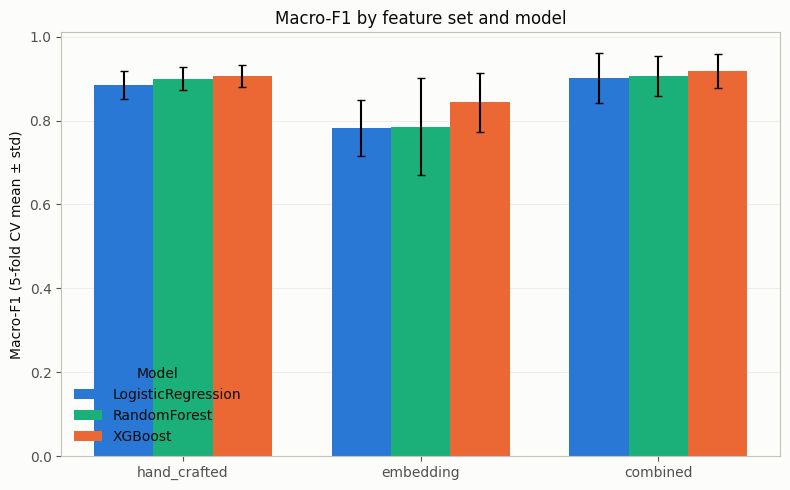

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(FEATURE_SET_ORDER))
width = 0.25
for i, model_name in enumerate(MODEL_ORDER):
    sub = summary[summary["model"] == model_name].set_index("feature_set").reindex(FEATURE_SET_ORDER)
    ax.bar(x + (i - 1) * width, sub["macro_f1_mean"], width,
           yerr=sub["macro_f1_std"], capsize=3,
           color=MODEL_COLORS[model_name], label=model_name)

ax.set_xticks(x)
ax.set_xticklabels(FEATURE_SET_ORDER)
ax.set_ylabel("Macro-F1 (5-fold CV mean ± std)")
ax.set_title("Macro-F1 by feature set and model")
ax.legend(title="Model", frameon=False)
ax.grid(axis="y", linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

## 9. Confusion matrix grid (3 models x 3 feature sets), out-of-fold predictions

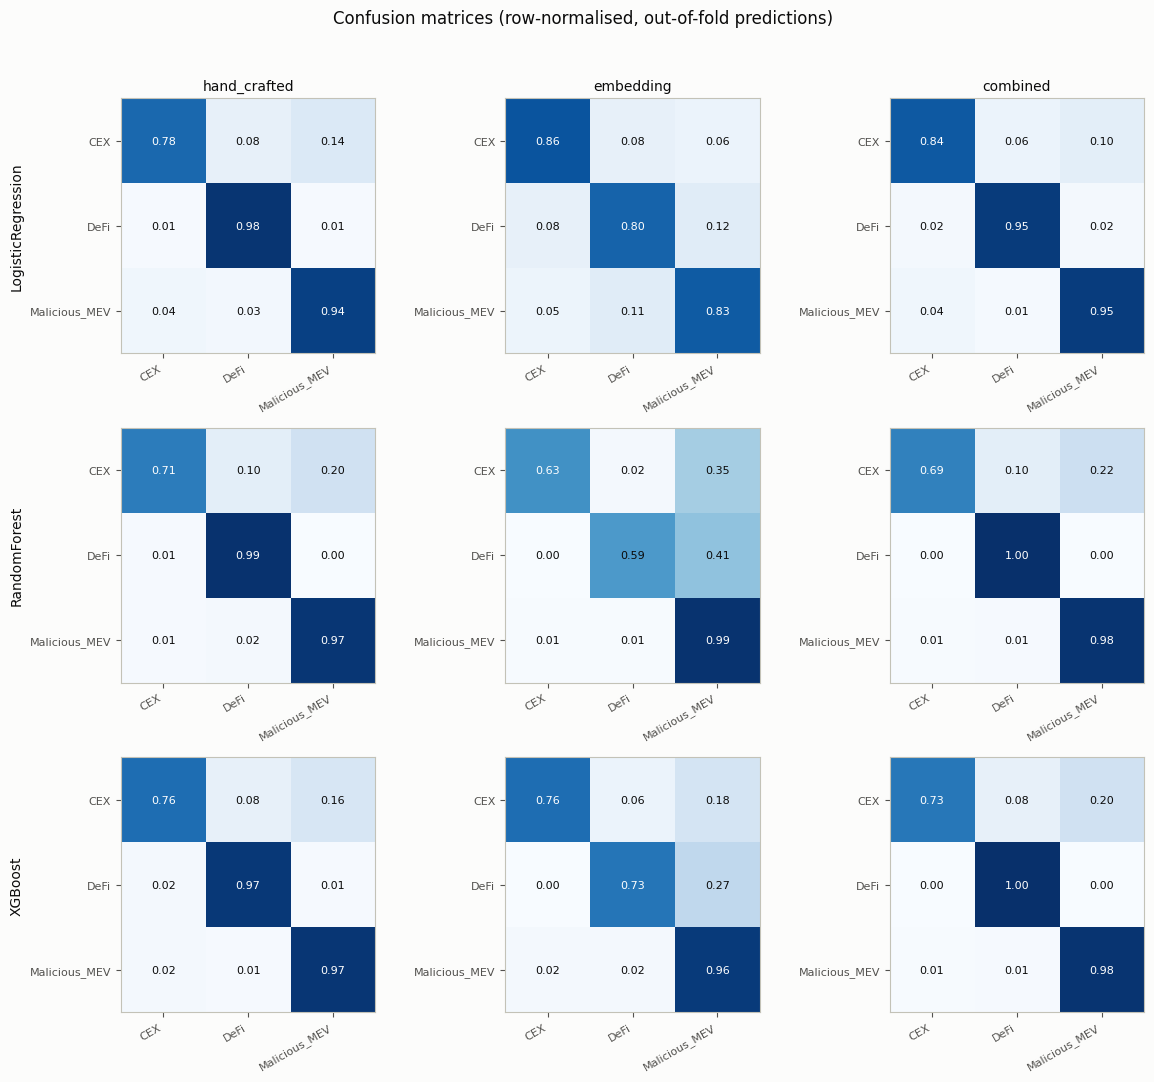

In [12]:
fig, axes = plt.subplots(len(MODEL_ORDER), len(FEATURE_SET_ORDER), figsize=(12, 11))
for row, model_name in enumerate(MODEL_ORDER):
    for col, fs_name in enumerate(FEATURE_SET_ORDER):
        ax = axes[row, col]
        y_pred_oof = oof_predictions[(fs_name, model_name)]
        cm = confusion_matrix(y, y_pred_oof, labels=LABEL_ORDER, normalize="true")
        im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
        for i in range(len(LABEL_ORDER)):
            for j in range(len(LABEL_ORDER)):
                text_color = "#ffffff" if cm[i, j] > 0.6 else "#0b0b0b"
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color=text_color)
        ax.set_xticks(range(len(LABEL_ORDER)))
        ax.set_xticklabels(LABEL_ORDER, rotation=30, ha="right", fontsize=8)
        ax.set_yticks(range(len(LABEL_ORDER)))
        ax.set_yticklabels(LABEL_ORDER, fontsize=8)
        if row == 0:
            ax.set_title(fs_name, fontsize=10)
        if col == 0:
            ax.set_ylabel(model_name, fontsize=10)

fig.suptitle("Confusion matrices (row-normalised, out-of-fold predictions)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.96])
display(fig)
plt.close(fig)

## 10. Feature-group contribution: does RF/LR actually use the embedding dimensions, or does the combined-set improvement come from elsewhere?


=== Feature-group contribution in the combined model (fit on all 436 seeds) ===
       group  n_features  share_of_all_features  RF_importance_share  LR_coef_share
hand_crafted          28                 0.3043               0.7405         0.3754
   embedding          64                 0.6957               0.2595         0.6246
RF: embedding gets far less importance mass than its feature-count share would predict -> RF already extracts the useful non-linear signal from hand-crafted features alone.
LR: embedding's coefficient share is roughly proportional to (or above) its feature-count share, and individual embedding dimensions rank among the top-10 |coef| features -> LR's linear boundary benefits from embedding dimensions in a way RF's tree ensemble does not need to. This is consistent with the paired-test result: XGBoost/LR show some (weak, n=5-limited) gain from combining, RF shows none.


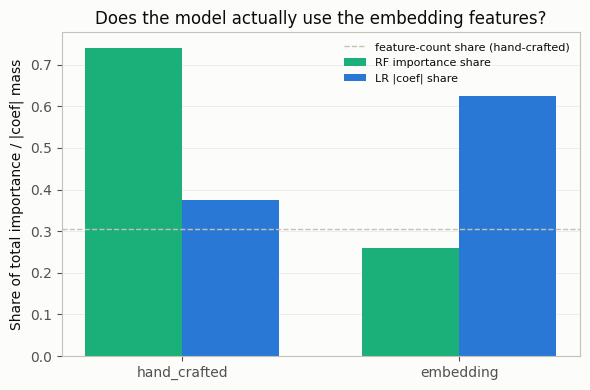


=== Week 8 baseline classification complete ===


In [13]:
# Fit RF and LR once on the FULL 436-sample combined set (interpretability
# diagnostic only, not a held-out performance claim) and compare how much
# importance/coefficient mass falls on hand_crafted vs embedding features.
# This directly tests whether "combined helps" reflects embeddings carrying
# independent structural signal, or the combined gain (where it exists) is
# concentrated in models that can't otherwise capture feature interactions.

all_cols = handcrafted_cols + emb_cols
col_group = ["hand_crafted"] * len(handcrafted_cols) + ["embedding"] * len(emb_cols)

rf_full = build_rf()
rf_full.fit(X_combined, y)
rf_imp = pd.DataFrame({"feature": all_cols, "group": col_group, "importance": rf_full.feature_importances_})

lr_full = build_lr()
lr_full.fit(X_combined, y)
lr_coef = np.abs(lr_full.named_steps["clf"].coef_).mean(axis=0)  # mean |coef| across classes (features are standardized, so comparable)
lr_imp = pd.DataFrame({"feature": all_cols, "group": col_group, "mean_abs_coef": lr_coef})

rf_group_mass = rf_imp.groupby("group")["importance"].sum()
lr_group_mass = lr_imp.groupby("group")["mean_abs_coef"].sum() / lr_imp["mean_abs_coef"].sum()

feature_group_contribution = pd.DataFrame({
    "group": ["hand_crafted", "embedding"],
    "n_features": [len(handcrafted_cols), len(emb_cols)],
    "share_of_all_features": [len(handcrafted_cols) / len(all_cols), len(emb_cols) / len(all_cols)],
    "RF_importance_share": [rf_group_mass.get("hand_crafted", 0), rf_group_mass.get("embedding", 0)],
    "LR_coef_share": [lr_group_mass.get("hand_crafted", 0), lr_group_mass.get("embedding", 0)],
}).round(4)
# Displayed inline; external export omitted.

print(f"\n=== Feature-group contribution in the combined model (fit on all 436 seeds) ===")
print(feature_group_contribution.to_string(index=False))
print("RF: embedding gets far less importance mass than its feature-count share would predict "
      "-> RF already extracts the useful non-linear signal from hand-crafted features alone.")
print("LR: embedding's coefficient share is roughly proportional to (or above) its feature-count "
      "share, and individual embedding dimensions rank among the top-10 |coef| features -> LR's "
      "linear boundary benefits from embedding dimensions in a way RF's tree ensemble does not "
      "need to. This is consistent with the paired-test result: XGBoost/LR show some (weak, "
      "n=5-limited) gain from combining, RF shows none.")

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(2)
width = 0.35
ax.bar(x - width / 2, feature_group_contribution["RF_importance_share"], width, color=MODEL_COLORS["RandomForest"], label="RF importance share")
ax.bar(x + width / 2, feature_group_contribution["LR_coef_share"], width, color=MODEL_COLORS["LogisticRegression"], label="LR |coef| share")
ax.axhline(feature_group_contribution.loc[0, "share_of_all_features"], color="#c3c2b7", linestyle="--", linewidth=1, label="feature-count share (hand-crafted)")
ax.set_xticks(x)
ax.set_xticklabels(feature_group_contribution["group"])
ax.set_ylabel("Share of total importance / |coef| mass")
ax.set_title("Does the model actually use the embedding features?")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="y", linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

print("\n=== Week 8 baseline classification complete ===")

## Key result tables

In [14]:
display(summary)
display(paired_sig_df)
display(per_class_df)
display(feature_group_contribution)

,feature_set,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,hand_crafted,LogisticRegression,0.8847,0.0337,0.8982,0.0327
1,hand_crafted,RandomForest,0.9000,0.0279,0.8884,0.0231
2,hand_crafted,XGBoost,0.9065,0.0259,0.9005,0.0296
3,embedding,LogisticRegression,0.7820,0.0661,0.8324,0.0731
4,embedding,RandomForest,0.7855,0.1163,0.7344,0.1292
5,embedding,XGBoost,0.8433,0.0698,0.8179,0.0770
6,combined,LogisticRegression,0.9022,0.0600,0.9151,0.0463
7,combined,RandomForest,0.9069,0.0475,0.8890,0.0423
8,combined,XGBoost,0.9177,0.0405,0.9017,0.0458


,model,mean_diff_combined_minus_handcrafted,paired_t_stat,paired_p_value,n_folds_improved
0,LogisticRegression,0.0175,0.8773,0.4299,2
1,RandomForest,0.0070,0.7342,0.5036,4
2,XGBoost,0.0112,0.5392,0.6183,4


,feature_set,model,label,precision,recall,f1,support
0,hand_crafted,LogisticRegression,CEX,0.7692,0.7843,0.7767,51
1,hand_crafted,LogisticRegression,DeFi,0.8750,0.9767,0.9231,86
2,hand_crafted,LogisticRegression,Malicious_MEV,0.9722,0.9365,0.9540,299
3,hand_crafted,RandomForest,CEX,0.9000,0.7059,0.7912,51
4,hand_crafted,RandomForest,DeFi,0.8947,0.9884,0.9392,86
5,hand_crafted,RandomForest,Malicious_MEV,0.9668,0.9732,0.9700,299
6,hand_crafted,XGBoost,CEX,0.8478,0.7647,0.8041,51
7,hand_crafted,XGBoost,DeFi,0.9222,0.9651,0.9432,86
8,hand_crafted,XGBoost,Malicious_MEV,0.9700,0.9732,0.9716,299
9,embedding,LogisticRegression,CEX,0.6567,0.8627,0.7458,51


,group,n_features,share_of_all_features,RF_importance_share,LR_coef_share
0,hand_crafted,28,0.3043,0.7405,0.3754
1,embedding,64,0.6957,0.2595,0.6246


## Interpretation

The five-fold results establish the baseline model ranking and motivate the repeat-level inference in `02_repeated_cv.ipynb`.